In [1]:
import os, sys, glob
os.environ["CUDA_VISIBLE_DEVICES"] = "0"

WORK = "/kaggle/working"
DATA_DIR = f"{WORK}/data"
OUT_DIR = f"{WORK}/outputs"
RESULTS_DIR = f"{WORK}/results"
for d in (DATA_DIR, OUT_DIR, RESULTS_DIR):
    os.makedirs(d, exist_ok=True)

def find(name):
    hits = sorted(glob.glob(f"{WORK}/**/{name}", recursive=True)) + \
           sorted(glob.glob(f"/kaggle/input/**/{name}", recursive=True))
    if not hits:
        raise FileNotFoundError(f"{name} not found: attach the dataset/notebook that makes it (Add Input)")
    if len(hits) > 1:
        print(f"note: {len(hits)} copies of {name}, using {hits[0]}")
    return hits[0]

RAW_CSV = find("afri_med_qa_15k_v2.4_phase_2_15275.csv")

HF_USER = "Tresor26"
def hub_id(run_name):
    return f"{HF_USER}/clinicmate-{run_name}"

from kaggle_secrets import UserSecretsClient
from huggingface_hub import login
login(token=UserSecretsClient().get_secret("HF_TOKEN"))

REPO = "/kaggle/temp/ClinicMate"
if not os.path.exists(REPO):
    !git clone -q https://github.com/Tresorshingiro/ClinicMate.git {REPO}
else:
    !git -C {REPO} pull -q
sys.path.append(REPO)

import random, numpy as np
SEED = 42
random.seed(SEED); np.random.seed(SEED)

In [2]:
import json
import pandas as pd, matplotlib.pyplot as plt
raw = pd.read_csv(RAW_CSV)
print(raw.shape)

(15275, 29)


In [3]:
print(raw["question_type"].value_counts())
print(pd.crosstab([raw["question_type"], raw["tier"]], raw["split"]))

question_type
consumer_queries    10000
mcq                  4039
saq                  1236
Name: count, dtype: int64
split                          test  train
question_type    tier                     
consumer_queries crowdsourced  1634   8366
mcq              crowdsourced     0    129
                 expert        3910      0
saq              crowdsourced     0    877
                 expert         359      0


In [5]:
for qt in raw["question_type"].unique():
    r = raw[raw["question_type"] == qt].iloc[0]
    print(f"\n===== {qt} =====")
    for col in ["prompt", "question", "answer_options", "correct_answer", "answer_rationale"]:
        print(f"--- {col}: {repr(r[col])[:300]}")


===== consumer_queries =====
--- prompt: 'Your female friend complains of weight gain, high blood pressure and thinks she has Lupus Nephritis and is going to visit the nearest doctor. Question: '
--- question: 'Can you provide recommendations for managing stress and improving mental well-being in relation to my condition?'
--- answer_options: nan
--- correct_answer: nan
--- answer_rationale: nan

===== mcq =====
--- prompt: nan
--- question: 'Which of the following conditions is characterized by an abnormal enlargement of the thyroid gland, often resulting in a visibly enlarged neck, and is endemic in certain regions of Africa due to dietary iodine deficiency?'
--- answer_options: '{"option1": "Hashimoto\'s thyroiditis", "option2": "Graves\' disease", "option3": "Toxic multinodular goiter", "option4": "Simple (nontoxic) goiter", "option5": "Thyroid cancer"}'
--- correct_answer: 'option4'
--- answer_rationale: "Simple (nontoxic) goiter is characterized by thyroid enlargement without as

In [7]:
def nonempty(s): return s.fillna("").astype(str).str.strip().ne("").mean().round(3)
print(raw.groupby("question_type")[["prompt", "answer_options", "correct_answer", "answer_rationale"]].agg(nonempty))

                  prompt  answer_options  correct_answer  answer_rationale
question_type                                                             
consumer_queries     1.0             0.0             0.0             0.017
mcq                  0.0             1.0             1.0             0.076
saq                  0.0             0.0             0.0             1.000


                    count       mean        std  min   25%   50%   75%    max
question_type                                                                
consumer_queries  10000.0   0.264200   2.366254  0.0   0.0   0.0   0.0   38.0
mcq                4039.0   2.360733  12.104623  0.0   0.0   0.0   0.0  211.0
saq                1236.0  42.881877  55.099018  1.0  21.0  29.0  43.0  900.0


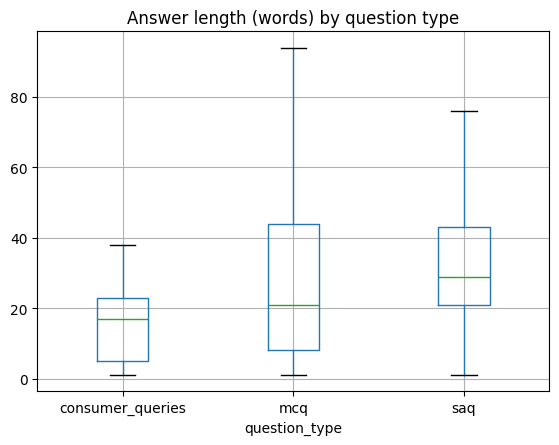

In [8]:
raw["answer_words"] = raw["answer_rationale"].fillna("").str.split().str.len()
print(raw.groupby("question_type")["answer_words"].describe())
raw[raw.answer_words > 0].boxplot(column="answer_words", by="question_type", showfliers=False)
plt.title("Answer length (words) by question type")
plt.suptitle("")
plt.savefig(f"{RESULTS_DIR}/eda_answer_length.png", dpi=150, bbox_inches="tight")
plt.show()

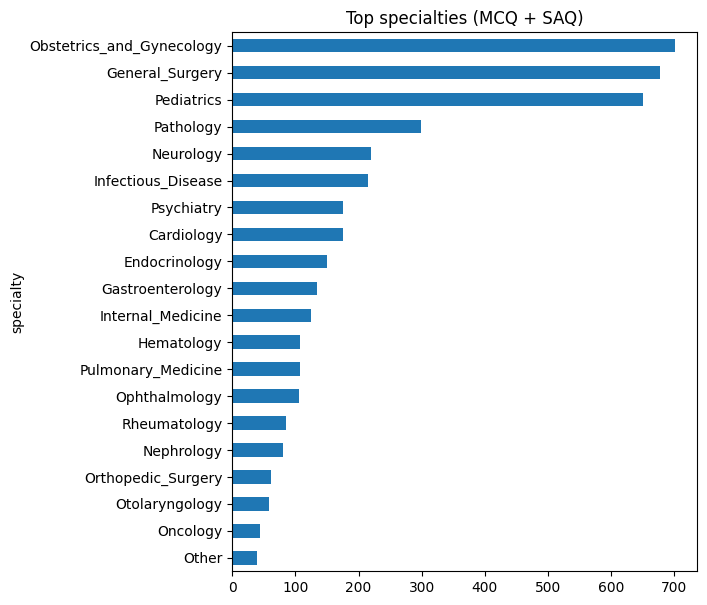

country
NG    7577
KE    2476
ZA    2444
GH    1572
MW     465
PH     320
UG     175
MZ      77
TZ      36
LS      33
Name: count, dtype: int64


In [10]:
raw[raw.question_type != "consumer_queries"]["specialty"].value_counts().head(20).plot.barh(figsize=(6, 7))
plt.title("Top specialties (MCQ + SAQ)")
plt.gca().invert_yaxis()
plt.savefig(f"{RESULTS_DIR}/eda_specialty.png", dpi=150, bbox_inches="tight")
plt.show()
print(raw["country"].value_counts().head(10))

In [11]:
from src.data import parse_options, parse_correct
mcq = raw[raw.question_type == "mcq"].copy()
mcq["opts"] = mcq["answer_options"].map(parse_options)
mcq["ans"] = [parse_correct(c, o) for c, o in zip(mcq["correct_answer"], mcq["opts"])]
print("non-empty options:", mcq["opts"].str.len().value_counts().to_dict())
print("number of correct answers:", mcq["ans"].str.len().value_counts().to_dict())
print("letter distribution:", mcq.loc[mcq["ans"].str.len() == 1, "ans"].str[0].value_counts(normalize=True).round(3).to_dict())

non-empty options: {5: 3122, 4: 898, 2: 14, 3: 4, 0: 1}
number of correct answers: {1: 3725, 3: 127, 2: 114, 4: 57, 5: 13, 0: 3}
letter distribution: {'C': 0.237, 'B': 0.223, 'D': 0.216, 'A': 0.208, 'E': 0.116}


In [12]:
key = raw["question"].fillna("").str.lower().str.replace(r"[^a-z0-9]", "", regex=True)
print("duplicate questions by type:", raw[key.duplicated(keep=False)].groupby("question_type").size().to_dict())

duplicate questions by type: {'consumer_queries': 765, 'mcq': 2, 'saq': 1}
